# Predição de preços de imóveis: criação do conjunto de dados por *scraping*

**Etapa 1 do trabalho:** encontrar ou criar um conjunto de dados que permita prever o preço de imóveis.

**Autor:** Vinicius Machado

Este notebook registra o processo completo: quais fontes foram consideradas, como os dados foram **coletados por *scraping*** no site do QuintoAndar, por que uma base foi escolhida para a modelagem, como ela foi inspecionada e limpa, e uma prova de conceito mostrando que ela de fato permite prever preços. A ideia é que dê para ler de cima a baixo e entender cada decisão sem precisar de explicações externas.

**Sumário**

1. Definição do problema
2. Fontes de dados candidatas
3. Extração: *scraping* próprio e base de referência
4. Inspeção inicial
5. Diagnóstico de qualidade
6. Limpeza e preparação
7. Análise exploratória orientada à predição
8. Prova de conceito: a base permite prever preços?
9. Base final para modelagem
10. Conclusão

## 0. Ambiente: bibliotecas e configurações

Usamos só bibliotecas que já vêm instaladas no Google Colab:

- `pandas` e `numpy` para manipular os dados;
- `matplotlib` e `seaborn` para os gráficos;
- `requests` para o *scraping* (seção 3) e `urllib.robotparser`, da biblioteca padrão, para consultar as regras de acesso do site;
- `scikit-learn` para a prova de conceito com modelos de regressão (seção 8).

As versões são impressas para fins de reprodutibilidade. A semente aleatória (`SEMENTE`) é fixada para que a divisão treino/teste e os modelos deem sempre o mesmo resultado.

In [1]:
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
import seaborn as sns
import sklearn

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
sns.set_theme(style="whitegrid")

SEMENTE = 42

print(f"Python       : {sys.version.split()[0]}")
print(f"pandas       : {pd.__version__}")
print(f"numpy        : {np.__version__}")
print(f"requests     : {requests.__version__}")
print(f"scikit-learn : {sklearn.__version__}")

Python       : 3.14.7
pandas       : 3.0.5
numpy        : 2.5.2
requests     : 2.34.2
scikit-learn : 1.9.1


# 1. Definição do problema

## 1.1 O que queremos prever

O objetivo é estimar o **preço de venda** de um imóvel a partir das suas características: localização, tamanho, número de cômodos, vagas, itens de lazer etc. Em termos de *machine learning*, é um problema de **regressão supervisionada**: precisamos de exemplos de imóveis com o preço conhecido (a variável-alvo) para que um modelo aprenda a relação entre as características e o preço.

## 1.2 O que um bom conjunto de dados precisa ter

Antes de procurar as bases, definimos os critérios que vão orientar a escolha. Assim, a decisão fica justificada e não depende de preferência pessoal.

| # | Critério | Por que importa |
|---|---|---|
| C1 | **Variável-alvo clara**: preço de **venda** | Misturar aluguel e venda, ou usar só aluguel, muda o problema |
| C2 | **Atributos explicativos** relevantes: área, quartos, banheiros, vagas, localização, lazer | Sem eles o modelo não tem de onde aprender |
| C3 | **Volume** suficiente (milhares de registros) | Mais exemplos permitem modelos mais robustos e uma avaliação confiável |
| C4 | **Atualidade** | Preço de imóvel muda com o tempo; dados antigos descrevem outro mercado |
| C5 | **Acesso reprodutível** | Qualquer pessoa deve conseguir rodar o notebook do zero, sem login nem *upload* manual |
| C6 | **Qualidade** razoável | Poucos ausentes e erros que possam ser tratados com regras claras |

# 2. Fontes de dados candidatas

## 2.1 As opções levantadas

Foram consideradas quatro fontes:

**A. Imóveis de São Paulo, abril de 2019 (Kaggle)**
cerca de 13 mil registros com `Price`, `Condo`, `Size`, `Rooms`, `Toilets`, `Suites`, `Parking`, `Elevator`, `Furnished`, `Swimming Pool`, `New`, `District`, `Negotiation Type`, `Property Type`, `Latitude` e `Longitude`.
<https://www.kaggle.com/datasets/argonalyst/sao-paulo-real-estate-sale-rent-april-2019>

**B. Imóveis de São Paulo, 2023, QuintoAndar (Kaggle)**
quase 12 mil registros com `Address`, `District`, `Area`, `Bedrooms`, `Garage`, `Rent`, `Type` e `Total`.
<https://www.kaggle.com/datasets/renatosn/sao-paulo-housing-prices>

**C. Biblioteca `dadosimob` (GitHub)**
biblioteca Python que busca dados públicos e atualizados de transações de imóveis.
<https://github.com/Rafaxdz-1000/dadosimob>

**D. Imóveis à venda no Rio de Janeiro, outubro de 2026, QuintoAndar (base de referência do professor)**
coleta de anúncios de venda do QuintoAndar no município do Rio, feita em 05/10/2026 e disponível em CSV público.
<https://raw.githubusercontent.com/alvaroriz/datascience_datasets/refs/heads/main/quintoandar_rio_20261005.csv>

**E. Coleta própria por *scraping* do QuintoAndar (Rio de Janeiro, outubro de 2026)**
a base que **nós mesmos criamos** na seção 3, com um *scraper* escrito neste notebook. Ela traz as variáveis que a etapa de análise de qualidade exige: preço, condomínio e IPTU **separados**, metragem, bairro e **rua**.

## 2.2 Comparação pelos critérios

| Critério | A. SP 2019 | B. SP 2023 | C. `dadosimob` | D. Rio 2026 (professor) | E. Rio 2026 (coleta própria) |
|---|---|---|---|---|---|
| C1 Alvo = preço de venda | Parcial: mistura venda e aluguel (`Negotiation Type`), só uma parte é venda | **Não**: só aluguel (`Rent`, `Total`) | Sim: valor de transação | **Sim**: só venda | **Sim**: só venda |
| C2 Atributos | Bons, inclusive coordenadas | Poucos: área, quartos, vagas, tipo | Dependem da fonte consultada; em geral poucos atributos físicos | **Bons**: área, cômodos, vagas, condomínio + IPTU, lazer, bairro e região | **Bons**, e com **rua** e **condomínio e IPTU separados** |
| C3 Volume | ~13 mil, menos depois de filtrar só venda | ~12 mil | Variável | **~41 mil**, todas as faixas de preço | ~18 mil: só anúncios próprios do QuintoAndar, até R$ 1 milhão |
| C4 Atualidade | 2019, defasada | 2023 | Atual | Outubro de 2026 | **Outubro de 2026** (a data de execução) |
| C5 Acesso reprodutível | Exige conta no Kaggle | Exige conta no Kaggle | Depende de instalação e de serviços externos | **URL pública direta** | O código está no notebook, mas o resultado muda a cada execução, e o site pode mudar ou bloquear |

## 2.3 Decisão

**Usamos a base E, a coleta própria, como conjunto de dados do trabalho.** A seção 3 documenta o *scraping* do início ao fim, as seções 4 a 9 preparam e testam essa base para a predição, e a etapa 2 analisa a qualidade dela em profundidade. O fluxo fica coerente: coletar, avaliar e modelar os mesmos dados.

A base E tem limitações conhecidas: ela cobre só imóveis de até R$ 1 milhão e só os anúncios próprios do QuintoAndar. O modelo, portanto, vale para esse segmento do mercado. Mesmo assim, com cerca de 18 mil anúncios, ela tem volume de sobra para a prova de conceito.

**A base D (referência do professor) tem outro papel: validar o *scraper*.** Por ser da mesma plataforma, os anúncios presentes nas duas bases devem ter os mesmos valores. A comparação é feita na seção 3.8.

As fontes A, B e C não são descartadas por serem ruins: a base A seria uma boa alternativa para São Paulo se filtrássemos só os anúncios de venda, e a `dadosimob` é interessante para complementar com transações reais (o preço anunciado não é necessariamente o preço fechado). Essa limitação das bases D e E é registrada na conclusão.

O critério C6 (qualidade) não pode ser avaliado antes de abrir os dados. É o que fazemos nas seções 4 e 5 (e, para a coleta própria, no notebook da etapa 2).

# 3. Extração: *scraping* próprio e base de referência

Esta seção cria o nosso próprio conjunto de dados, coletando os anúncios de venda do Rio de Janeiro diretamente do site do QuintoAndar. O processo é documentado na ordem em que foi feito: entender o site, verificar o que é permitido coletar, descobrir de onde vêm os dados, escrever o *scraper*, executar a coleta, organizar e gravar o resultado e, por fim, conferir se os dados coletados estão corretos.

## 3.1 O que coletar

O alvo são os **imóveis à venda no município do Rio de Janeiro com preço de até R$ 1.000.000**, o limite de preço definido para a coleta. Para cada anúncio, queremos as variáveis que a etapa de análise de qualidade exige, mais os atributos úteis para a predição:

| Variável | Campo no site | Coluna no CSV |
|---|---|---|
| Preço | `salePrice` | `preco` |
| Valor do condomínio | `condominium` | `condominio` |
| Valor do IPTU | `iptu` | `iptu` |
| Metragem quadrada | `area` | `area_m2` |
| Bairro | `neighbourhood` | `bairro` |
| Rua | `address` | `rua` |
| Tipo, quartos, banheiros, suítes, vagas, mobília, lazer | `type`, `bedrooms`, `bathrooms`, `suites`, `parkingSpaces`, `isFurnished`, `installations`, `amenities` | `tipo`, `quartos`, ... |

## 3.2 Investigação do site

Antes de escrever qualquer código de coleta, é preciso entender **como o site entrega os dados**. Os passos abaixo descrevem a investigação, e as células seguintes reproduzem em código o que foi encontrado.

1. **A página de busca** <https://www.quintoandar.com.br/comprar/imovel/rio-de-janeiro-rj-brasil/de-0-a-1000000-venda> mostra os imóveis à venda no Rio até R$ 1 milhão, já com o filtro de preço na própria URL.
2. **O código-fonte da página** revela que o site é feito em Next.js: os dados dos anúncios vêm embutidos em um bloco JSON, `<script id="__NEXT_DATA__">`. Isso é ótimo para o *scraping*, porque evita ter de "garimpar" os valores no meio do HTML.
3. **Mas esse bloco só traz cerca de duas dezenas de anúncios.** Os demais são carregados à medida que o usuário rola a página. Um parâmetro como `?pagina=2` é ignorado pelo site.
4. **Os arquivos JavaScript do site** (os `_next/static/chunks/*.js` carregados pela página) mostram de onde vêm os anúncios seguintes: requisições `POST` para uma API interna, `https://apigw.prod.quintoandar.com.br/house-listing-search/v2/search/list`, que recebe os filtros em JSON e devolve os anúncios também em JSON. O mesmo código revela o formato do corpo da requisição: os filtros, a paginação e a lista de campos (`fields`) que o site pede. A mesma descoberta poderia ser feita pela aba *Network* das ferramentas de desenvolvedor do navegador (F12), observando as requisições durante a rolagem.

### Regras de acesso: `robots.txt`

O arquivo `robots.txt` é o modo padrão de um site informar o que robôs podem ou não acessar. Ele é consultado antes da coleta:

In [2]:
from urllib import robotparser

SITE = "https://www.quintoandar.com.br"
regras = robotparser.RobotFileParser(f"{SITE}/robots.txt")
regras.read()

for caminho in ["/comprar/imovel/rio-de-janeiro-rj-brasil/de-0-a-1000000-venda",
                "/imovel/895781334/comprar",
                "/busca",
                "/classificado/124757982/comprar"]:
    print(f"{'permitido' if regras.can_fetch('*', SITE + caminho) else 'BLOQUEADO':10s} {caminho}")

permitido  /comprar/imovel/rio-de-janeiro-rj-brasil/de-0-a-1000000-venda
permitido  /imovel/895781334/comprar
BLOQUEADO  /busca
BLOQUEADO  /classificado/124757982/comprar


As páginas de busca e de imóvel são **permitidas**. Já `/busca` e as páginas de **classificados** (anúncios de terceiros publicados na plataforma) são **bloqueadas**. Por isso, a coleta se limita aos **anúncios próprios do QuintoAndar** e não inclui os classificados. A API (`apigw.prod.quintoandar.com.br`) é um domínio separado e não publica um `robots.txt`.

### Primeira tentativa: ler os dados embutidos na página

A forma mais simples de *scraping* é baixar a página e extrair o bloco `__NEXT_DATA__`. A célula abaixo faz isso e mostra tanto o que funciona quanto o limite dessa abordagem:

In [3]:
import json
import re
import time

CABECALHOS = {
    # Identificamos o robô de forma transparente, em vez de nos passarmos por um navegador
    "User-Agent": "Mozilla/5.0 (compatible; trabalho-academico-scraping/1.0)",
    "Accept": "application/json",
    "Content-Type": "application/json",
    "Origin": SITE,
    "Referer": SITE + "/",
}
URL_BUSCA = f"{SITE}/comprar/imovel/rio-de-janeiro-rj-brasil/de-0-a-1000000-venda"

pagina = requests.get(URL_BUSCA, headers=CABECALHOS, timeout=30)
bloco = re.search(r'<script id="__NEXT_DATA__"[^>]*>(.*?)</script>', pagina.text, re.S).group(1)
estado = json.loads(bloco)["props"]["pageProps"]["initialState"]

print(f"Status HTTP: {pagina.status_code} | tamanho da página: {len(pagina.text) / 1e6:.1f} MB")
print(f"Imóveis que o site diz existir na busca: {estado['search']['visibleHouses']['total']:,}")
print(f"Imóveis cujos dados vieram na página    : {len(estado['houses'])}")

exemplo = next(iter(estado["houses"].values()))
{k: exemplo.get(k) for k in ["id", "salePrice", "condoIptu", "area", "address", "neighbourhood", "type", "bedrooms"]}

Status HTTP: 200 | tamanho da página: 0.9 MB
Imóveis que o site diz existir na busca: 27,552
Imóveis cujos dados vieram na página    : 26


{'id': '892924208',
 'salePrice': 237900,
 'condoIptu': 573,
 'area': 49,
 'address': {'address': 'Avenida Tenente Coronel Muniz de Aragão',
  'city': 'Rio de Janeiro'},
 'neighbourhood': 'Anil',
 'type': 'Apartamento',
 'bedrooms': 2}

A página traz todos os campos de que precisamos, inclusive a rua, mas só para cerca de duas dezenas de imóveis, enquanto a busca tem dezenas de milhares (o total inclui os classificados). Para coletar o restante, usamos a mesma API que o site usa ao rolar a página.

## 3.3 O *scraper*

O *scraper* é composto de três funções:

- `montar_corpo`: monta o JSON da requisição, com o filtro de preço (e, se necessário, de área) e a paginação;
- `consultar`: envia a requisição e devolve o total de resultados e a lista de anúncios;
- `coletar_faixa`: percorre todas as faixas de preço, contornando as limitações da API (seção 3.4).

**Boas práticas adotadas**, para não sobrecarregar o site e coletar de forma responsável:

- **pausa** de 1,5 segundo antes de cada requisição, e uma requisição de cada vez (nada em paralelo). A coleta inteira faz cerca de 160 requisições em 5 minutos;
- **novas tentativas com espera crescente** (3 s, 6 s, 12 s...) em caso de erro de conexão, de limite de requisições (HTTP 429) ou de falha do servidor. O *scraper* não insiste em ritmo acelerado;
- **identificação transparente** do robô no cabeçalho `User-Agent`;
- **apenas os campos necessários** (parâmetro `fields`). Não são coletados nome, telefone ou e-mail de anunciantes. O endereço vem, na maioria dos anúncios, só com o nome da rua. Alguns anunciantes, porém, digitam número e até apartamento nesse campo (etapa 2, seção 7.2);
- **sem login** e sem contornar nenhum bloqueio.

In [4]:
URL_API = "https://apigw.prod.quintoandar.com.br/house-listing-search/v2/search/list"
SLUG_CIDADE = "rio-de-janeiro-rj-brasil"
PRECO_MAXIMO = 1_000_000   # limite de preço definido para a coleta
LIMITE_POR_CONSULTA = 500  # maior página que a API aceita (seção 3.4)
PAUSA = 1.5                # segundos entre requisições

CAMPOS = ["id", "type", "salePrice", "condominium", "iptu", "iptuPlusCondominium", "area", "address",
          "neighbourhood", "regionName", "city", "bedrooms", "bathrooms", "suites", "parkingSpaces",
          "isFurnished", "installations", "amenities"]

sessao = requests.Session()
sessao.headers.update(CABECALHOS)
contador = {"requisicoes": 0}


def montar_corpo(faixa_preco, faixa_area=None, offset=0, tamanho=LIMITE_POR_CONSULTA):
    """JSON enviado à API, no mesmo formato que o site usa."""
    filtros = {
        "businessContext": "SALE",
        "enableFlexibleSearch": True,
        "houseIds": [],
        "propertyBlocklist": [],
        "priceRange": [{"costType": "SALE_PRICE", "range": {"min": faixa_preco[0], "max": faixa_preco[1]}}],
    }
    if faixa_area:
        filtros["houseSpecs"] = {"area": {"range": {"min": faixa_area[0], "max": faixa_area[1]}}}
    return {
        "context": {"isSSR": False, "viewMode": "list"},
        "filters": filtros,
        "location": {"countryCode": "BR"},
        "sorting": {"sortMode": "MOST_RECENT"},
        "pagination": {"page": offset // tamanho, "pageSize": tamanho, "offset": offset},
        "fields": CAMPOS,
        "slug": SLUG_CIDADE,
        "locationDescriptions": [{"description": SLUG_CIDADE}],
    }


def consultar(faixa_preco, faixa_area=None, offset=0, tamanho=LIMITE_POR_CONSULTA, tentativas=5):
    """Faz uma requisição à API e devolve (total de resultados da busca, anúncios desta página)."""
    for tentativa in range(tentativas):
        time.sleep(PAUSA)
        contador["requisicoes"] += 1
        try:
            resposta = sessao.post(URL_API, json=montar_corpo(faixa_preco, faixa_area, offset, tamanho), timeout=30)
        except requests.RequestException as erro:
            motivo = type(erro).__name__
        else:
            if resposta.status_code == 200:
                hits = resposta.json()["hits"]
                return hits["total"]["value"], [h["_source"] for h in hits["hits"]]
            motivo = f"HTTP {resposta.status_code}"
        espera = PAUSA * 2 ** (tentativa + 1)
        print(f"  {motivo}: nova tentativa em {espera:.0f} s")
        time.sleep(espera)
    raise RuntimeError(f"A API não respondeu após {tentativas} tentativas")


total, anuncios = consultar((0, PRECO_MAXIMO), tamanho=2)
print(f"Anúncios próprios do QuintoAndar à venda no Rio até R$ 1 milhão: {total:,}")
print("\nUm anúncio como a API devolve (JSON bruto):")
print(json.dumps(anuncios[0], ensure_ascii=False, indent=1)[:900])

Anúncios próprios do QuintoAndar à venda no Rio até R$ 1 milhão: 18,295

Um anúncio como a API devolve (JSON bruto):
{
 "id": 893307694,
 "type": "Apartamento",
 "area": 75,
 "bathrooms": 2,
 "bedrooms": 2,
 "suites": 2,
 "parkingSpaces": 2,
 "amenities": [
  "ESPELHO_NO_BANHEIRO",
  "CORTINAS_BLACK_OUT",
  "FOGAO_INCLUSO",
  "CAMA_DE_CASAL",
  "SOL_DA_TARDE",
  "CAMA_DE_SOLTEIRO",
  "PODE_TER_ANIMAIS_DE_ESTIMACAO",
  "TANQUE",
  "ENERGIA",
  "VARANDA",
  "GELADEIRA_INCLUSO",
  "ACESSO_SEM_DEGRAUS",
  "MESAS_E_CADEIRAS_DE_JANTAR",
  "VISTA_LIVRE",
  "TOMADAS_NOVAS",
  "ARMARIOS_NOS_BANHEIROS",
  "AR_CONDICIONADO",
  "BOX",
  "UTENSILIOS_DE_COZINHA",
  "CHUVEIRO_A_GAS",
  "SOFA",
  "ARMARIOS_EMBUTIDOS_NO_QUARTO",
  "ARMARIOS_NA_COZINHA",
  "LUMINOSIDADE_NATURAL"
 ],
 "installations": [
  "SALAO_DE_FESTAS",
  "ACADEMIA",
  "CHURRASQUEIRA",
  "GAS_ENCANADO",
  "PISCINA",
  "ESPACO_GOURMET_NA_AREA_COMUM",
  "PLAYGROUND",
  "SAUNA"
 ],
 "condominium": 1171,
 "iptu": 80,
 "iptuPlusCondominiu

## 3.4 As limitações da API e como contorná-las

Os primeiros testes revelaram três limitações:

1. **Página de no máximo 500 anúncios.** Um `pageSize` maior devolve o erro *"must be less than or equal to 500"*.
2. **No máximo 1.000 resultados por busca.** Pedir a página que começa no resultado 1.000 devolve *"Pagination exceeds the maximum limit"*.
3. **A paginação não é estável.** Ao percorrer uma busca página por página, a ordem dos resultados muda entre uma requisição e outra: alguns anúncios aparecem em duas páginas e outros não aparecem em nenhuma. A célula abaixo demonstra o problema em uma faixa estreita de preço:

In [5]:
FAIXA_TESTE = (480_001, 500_000)

total_teste, de_uma_vez = consultar(FAIXA_TESTE)
paginado = []
for offset in range(0, total_teste, 100):
    paginado += consultar(FAIXA_TESTE, offset=offset, tamanho=100)[1]

ids_uma_vez = {a["id"] for a in de_uma_vez}
ids_paginado = [a["id"] for a in paginado]
print(f"Anúncios na faixa (total informado pela API): {total_teste}")
print(f"Em uma única requisição : {len(de_uma_vez)} anúncios, {len(ids_uma_vez)} distintos")
print(f"Paginando de 100 em 100 : {len(ids_paginado)} anúncios, {len(set(ids_paginado))} distintos "
      f"({len(ids_paginado) - len(set(ids_paginado))} repetidos, {len(ids_uma_vez - set(ids_paginado))} perdidos)")

Anúncios na faixa (total informado pela API): 496
Em uma única requisição : 496 anúncios, 496 distintos
Paginando de 100 em 100 : 496 anúncios, 468 distintos (28 repetidos, 28 perdidos)


Paginar perde anúncios. Já uma única requisição de até 500 itens traz a faixa completa, sem repetições. A estratégia, portanto, é **nunca paginar**: dividir a busca em faixas pequenas o bastante para caberem inteiras em uma requisição.

1. Pede-se a faixa de R$ 0 a R$ 1.000.000 com página de 500.
2. Se a API informar até 500 resultados, a resposta já contém todos eles, e a faixa está coletada.
3. Se informar mais, a faixa é **dividida ao meio** (R$ 0 a 500 mil e R$ 500.001 a 1 milhão), e cada metade é tratada da mesma forma.
4. Se uma faixa chegar a um **único valor de preço** e ainda tiver mais de 500 imóveis (o que acontece, como veremos), ela passa a ser dividida pela **área**.

É uma busca binária recursiva. As faixas não se sobrepõem e, juntas, cobrem todo o intervalo. Mesmo assim, os anúncios são deduplicados pelo código ao final, por segurança. Se mais de 500 anúncios tivessem o mesmo preço **e** a mesma área, não haveria como dividir a faixa: nesse caso o *scraper* avisa e fica com os 500 que a API devolve. Isso não acontece nesta coleta, mas a proteção evita uma recursão infinita.

In [6]:
def coletar_faixa(faixa_preco, faixa_area=None, faixas_coletadas=None):
    """Coleta todos os anúncios da faixa, dividindo-a até que cada parte caiba em uma única requisição."""
    faixas_coletadas = [] if faixas_coletadas is None else faixas_coletadas
    total, anuncios = consultar(faixa_preco, faixa_area)
    if total <= LIMITE_POR_CONSULTA:
        faixas_coletadas.append((faixa_preco, faixa_area, total))
        return anuncios
    menor, maior = faixa_preco
    if menor < maior:  # divide pelo preço
        meio = (menor + maior) // 2
        partes = [((menor, meio), faixa_area), ((meio + 1, maior), faixa_area)]
    else:              # preço único com mais de 500 anúncios: divide pela área
        area_menor, area_maior = faixa_area or (0, 100_000)
        if area_menor == area_maior:  # mesmo preço e mesma área: não há como dividir mais
            print(f"  Aviso: {total} anúncios com preço {menor} e área {area_menor}; coletados só {len(anuncios)}")
            faixas_coletadas.append((faixa_preco, faixa_area, len(anuncios)))
            return anuncios
        meio = (area_menor + area_maior) // 2
        partes = [(faixa_preco, (area_menor, meio)), (faixa_preco, (meio + 1, area_maior))]
    return [anuncio for preco, area in partes for anuncio in coletar_faixa(preco, area, faixas_coletadas)]

## 3.5 Execução da coleta

A coleta completa leva alguns minutos, por causa das pausas entre as requisições. A variável `COLETAR` controla o comportamento:

- `COLETAR = True`: executa o *scraping* agora e grava um novo CSV com a data de hoje;
- `COLETAR = False`: não acessa o site e lê o CSV de uma coleta anterior (`ARQUIVO_COLETA_SALVA`).

Se o site estiver fora do ar ou bloquear a coleta, a célula avisa e usa o CSV salvo, para que o restante do notebook continue funcionando.

**A coleta oficial deste trabalho é a de 18/10/2026** (`quintoandar_rio_scraping_20261018.csv`). É ela que a modelagem (seções 4 a 9) e a etapa 2 analisam, para que os números citados no texto continuem valendo. Uma nova execução do *scraping* é gravada em **outro arquivo** (com data e hora no nome) e nunca sobrescreve a coleta oficial. Para modelar uma coleta nova, basta trocar `ARQUIVO_BASE` na seção 4.1.

In [7]:
COLETAR = True
ARQUIVO_COLETA_SALVA = "quintoandar_rio_scraping_20261018.csv"


def coletar():
    inicio, requisicoes_antes = time.time(), contador["requisicoes"]
    total_anunciado, _ = consultar((0, PRECO_MAXIMO), tamanho=1)
    faixas = []
    anuncios = coletar_faixa((0, PRECO_MAXIMO), faixas_coletadas=faixas)
    anuncios = list({a["id"]: a for a in anuncios}.values())  # deduplicação por segurança

    print(f"Total informado pela API: {total_anunciado:,} | anúncios distintos coletados: {len(anuncios):,}")
    print(f"Faixas coletadas: {len(faixas)} (das quais {sum(f[1] is not None for f in faixas)} divididas pela área)")
    print(f"Requisições: {contador['requisicoes'] - requisicoes_antes} | tempo: {(time.time() - inicio) / 60:.1f} min")
    return total_anunciado, faixas, anuncios


resultado_coleta = None
if COLETAR:
    try:
        resultado_coleta = coletar()
    except Exception as erro:
        print(f"Falha no scraping ({erro}). Será usado o arquivo {ARQUIVO_COLETA_SALVA}.")

Total informado pela API: 18,295 | anúncios distintos coletados: 18,079
Faixas coletadas: 81 (das quais 20 divididas pela área)
Requisições: 162 | tempo: 5.2 min


## 3.6 Organização em tabela e gravação do CSV

A API devolve uma lista de dicionários JSON. Ela é convertida em uma tabela com nomes de colunas em português. A lista de instalações do condomínio (`installations`) e de características do imóvel (`amenities`) vira indicadores 0/1 de piscina, academia, churrasqueira e varanda.

**Nenhum valor é corrigido nesta etapa**: os dados são gravados exatamente como o site os informa (inclusive códigos estranhos, como veremos). A avaliação e o tratamento da qualidade são assunto da etapa 2 do trabalho. Corrigir aqui esconderia os problemas da coleta.

In [8]:
import os


def organizar(anuncios, data_coleta):
    bruto = pd.DataFrame(anuncios)
    instalacoes = bruto["installations"].apply(lambda v: v if isinstance(v, list) else [])
    caracteristicas = bruto["amenities"].apply(lambda v: v if isinstance(v, list) else [])
    return pd.DataFrame({
        "id": bruto["id"],
        "url": SITE + "/imovel/" + bruto["id"].astype(str) + "/comprar",
        "tipo": bruto["type"],
        "rua": bruto["address"],
        "bairro": bruto["neighbourhood"],
        "regiao_qa": bruto["regionName"],  # agrupamento de bairros usado pelo próprio QuintoAndar
        "cidade": bruto["city"],
        "preco": bruto["salePrice"],
        "condominio": bruto["condominium"],
        "iptu": bruto["iptu"],
        "condominio_iptu": bruto["iptuPlusCondominium"],
        "area_m2": bruto["area"],
        "quartos": bruto["bedrooms"],
        "banheiros": bruto["bathrooms"],
        "suites": bruto["suites"],
        "vagas": bruto["parkingSpaces"],
        "mobiliado": bruto["isFurnished"].astype("boolean").astype("Int64"),
        "tem_piscina": instalacoes.apply(lambda v: int("PISCINA" in v)),
        "tem_academia": instalacoes.apply(lambda v: int("ACADEMIA" in v)),
        "tem_churrasqueira": instalacoes.apply(lambda v: int("CHURRASQUEIRA" in v)),
        "tem_varanda": caracteristicas.apply(lambda v: int("VARANDA" in v)),
        "data_coleta": data_coleta,
    })


if resultado_coleta is not None:
    total_anunciado, faixas, anuncios = resultado_coleta
    data_coleta = pd.Timestamp.today().strftime("%Y-%m-%d")
    df_scraping = organizar(anuncios, data_coleta)
    ARQUIVO_COLETA = f"quintoandar_rio_scraping_{data_coleta.replace('-', '')}.csv"
    if os.path.exists(ARQUIVO_COLETA):  # nunca sobrescreve uma coleta anterior
        ARQUIVO_COLETA = ARQUIVO_COLETA.replace(".csv", pd.Timestamp.now().strftime("_%H%M%S.csv"))
    df_scraping.to_csv(ARQUIVO_COLETA, index=False, encoding="utf-8")
    print(f"Arquivo gravado: {ARQUIVO_COLETA}")
else:
    ARQUIVO_COLETA = ARQUIVO_COLETA_SALVA
    df_scraping = pd.read_csv(ARQUIVO_COLETA, encoding="utf-8")
    total_anunciado = None
    print(f"Arquivo lido: {ARQUIVO_COLETA}")

print(f"{df_scraping.shape[0]:,} linhas x {df_scraping.shape[1]} colunas")
df_scraping.head()

Arquivo gravado: quintoandar_rio_scraping_20261018_161646.csv
18,079 linhas x 22 colunas


,id,url,tipo,rua,bairro,regiao_qa,cidade,preco,condominio,iptu,condominio_iptu,area_m2,quartos,banheiros,suites,vagas,mobiliado,tem_piscina,tem_academia,tem_churrasqueira,tem_varanda,data_coleta
0,894663275,https://www.quintoandar.com.br/imovel/89466327...,Apartamento,Rua Lima Drumond,Vaz Lobo,Irajá,Rio de Janeiro,125000,847,0,847,56,2,1,0.00,1,0,0,0,1,1,2026-10-18
1,893417758,https://www.quintoandar.com.br/imovel/89341775...,Apartamento,Rua José Sombra,Irajá,Irajá,Rio de Janeiro,125000,360,0,360,40,1,1,0.00,1,0,0,0,0,0,2026-10-18
2,893456342,https://www.quintoandar.com.br/imovel/89345634...,Casa,Rua Amandiu,Irajá,Irajá,Rio de Janeiro,166600,-1,0,0,65,2,1,0.00,0,0,0,0,0,1,2026-10-18
3,894763874,https://www.quintoandar.com.br/imovel/89476387...,Apartamento,Avenida Otávio Malta,Anil,Anil,Rio de Janeiro,150000,200,0,200,44,2,1,0.00,1,0,0,0,0,1,2026-10-18
4,895124729,https://www.quintoandar.com.br/imovel/89512472...,Apartamento,Rua Araújo Leitão,Grajaú,Engenho Novo,Rio de Janeiro,180000,1100,0,1100,55,2,1,0.00,1,1,1,0,1,1,2026-10-18


## 3.7 Conferência da coleta

Um *scraper* pode falhar em silêncio: páginas puladas, anúncios repetidos por causa da paginação, filtros que não foram aplicados. Por isso conferimos o resultado com verificações objetivas:

In [9]:
ids_repetidos = df_scraping["id"].duplicated().sum()
print(f"Anúncios coletados                 : {len(df_scraping):,}")
if total_anunciado:
    print(f"Total anunciado pela API           : {total_anunciado:,} "
          f"(cobertura de {df_scraping['id'].nunique() / total_anunciado:.1%})")
print(f"IDs repetidos                      : {ids_repetidos}")
print(f"Cidades presentes                  : {df_scraping['cidade'].value_counts().to_dict()}")
print(f"Preço mínimo e máximo              : R$ {df_scraping['preco'].min():,.0f} a R$ {df_scraping['preco'].max():,.0f}")
print(f"Anúncios acima do limite da coleta : {(df_scraping['preco'] > PRECO_MAXIMO).sum()}")
print(f"Bairros distintos                  : {df_scraping['bairro'].nunique()}")

if COLETAR and total_anunciado:
    # O total da API é coerente? Compara a busca inteira com a soma das suas duas metades
    metade_baixa = consultar((0, PRECO_MAXIMO // 2), tamanho=1)[0]
    metade_alta = consultar((PRECO_MAXIMO // 2 + 1, PRECO_MAXIMO), tamanho=1)[0]
    print(f"\nTotal da busca inteira: {total_anunciado:,} | soma das duas metades: {metade_baixa + metade_alta:,}")

Anúncios coletados                 : 18,079
Total anunciado pela API           : 18,295 (cobertura de 98.8%)
IDs repetidos                      : 0
Cidades presentes                  : {'Rio de Janeiro': 18072, 'Lins': 1}
Preço mínimo e máximo              : R$ 125,000 a R$ 1,000,000
Anúncios acima do limite da coleta : 0
Bairros distintos                  : 216



Total da busca inteira: 18,295 | soma das duas metades: 18,022


**Resultado da conferência:**

- **Cobertura de cerca de 99%.** A diferença (cerca de 200 anúncios) não é erro do *scraper*: o próprio total da API é incoerente. Como mostra a última linha acima, a busca de R$ 0 a R$ 1 milhão informa um total **maior** que a soma das buscas de R$ 0 a 500 mil e de R$ 500.001 a R$ 1 milhão, que juntas cobrem exatamente a mesma faixa. Como o *scraper* percorre todas as faixas menores, os anúncios "a mais" do total não aparecem em nenhuma delas. Nas faixas pequenas, em que verificamos anúncio por anúncio (seção 3.4), a soma das partes bate exatamente com o todo. Uma hipótese é que o total da API inclua anúncios que o filtro de preço não consegue alcançar, mas não foi possível confirmá-la.
- **Nenhum ID repetido** e **nenhum anúncio acima do limite** de R$ 1 milhão: a divisão em faixas funcionou.
- **Um anúncio tem a cidade "Lins"** em vez de "Rio de Janeiro". É um bairro do Rio (Lins de Vasconcelos) cadastrado no campo errado: o primeiro sinal de que os dados digitados pelos anunciantes têm problemas, analisados na etapa 2.
- Os **bairros distintos (mais de 200)** são mais do que se esperaria, um indício de grafias diferentes para o mesmo bairro, também analisado na etapa 2.

## 3.8 Base de referência e validação do *scraper*

A base do professor (fonte D) foi coletada no mesmo site em 05/10/2026. Ela é lida direto do repositório público e guardada em `df_ref`. O arquivo está em UTF-8, informado em `encoding="utf-8"` para que os acentos dos bairros sejam lidos corretamente.

Os anúncios presentes nas duas bases (o mesmo código de anúncio) permitem **validar o nosso *scraper***: se ele estiver lendo os campos corretamente, preço, área e quartos devem coincidir na grande maioria dos casos. As diferenças esperadas são as mudanças reais de preço feitas pelos anunciantes entre as duas datas.

In [10]:
URL = "https://raw.githubusercontent.com/alvaroriz/datascience_datasets/refs/heads/main/quintoandar_rio_20261005.csv"

df_ref = pd.read_csv(URL, encoding="utf-8")
print(f"Base de referência: {df_ref.shape[0]:,} linhas x {df_ref.shape[1]} colunas")

referencia = df_ref[(df_ref["origem"] == "quintoandar") & (df_ref["preco"] <= PRECO_MAXIMO)]
comum = df_scraping.merge(referencia, left_on="id", right_on="id_fonte", suffixes=("", "_ref"))
print(f"Anúncios próprios do QuintoAndar até R$ 1 milhão na referência: {len(referencia):,}")
print(f"Anúncios presentes nas duas bases: {len(comum):,}\n")

for nossa, ref in [("preco", "preco_ref"), ("area_m2", "area_m2_ref"), ("quartos", "quartos_ref"),
                   ("condominio_iptu", "condominio_iptu_ref"), ("bairro", "bairro_ref")]:
    print(f"{nossa:16s}: valor idêntico em {(comum[nossa] == comum[ref]).mean():.1%} dos anúncios em comum")

mudou = comum["preco"] != comum["preco_ref"]
variacao = comum.loc[mudou, "preco"] / comum.loc[mudou, "preco_ref"] - 1
print(f"\nAnúncios com preço diferente: {mudou.sum():,}, dos quais {(variacao < 0).mean():.0%} com preço menor hoje "
      f"(variação mediana de {variacao.median():.1%})")
print(f"Bairro idêntico ignorando espaços extras: {(comum['bairro'].str.strip() == comum['bairro_ref']).mean():.1%}")

Base de referência: 41,450 linhas x 22 colunas
Anúncios próprios do QuintoAndar até R$ 1 milhão na referência: 16,106
Anúncios presentes nas duas bases: 15,089

preco           : valor idêntico em 89.4% dos anúncios em comum
area_m2         : valor idêntico em 99.6% dos anúncios em comum
quartos         : valor idêntico em 99.9% dos anúncios em comum
condominio_iptu : valor idêntico em 98.9% dos anúncios em comum
bairro          : valor idêntico em 94.7% dos anúncios em comum

Anúncios com preço diferente: 1,601, dos quais 82% com preço menor hoje (variação mediana de -3.4%)
Bairro idêntico ignorando espaços extras: 94.8%


**O *scraper* está validado.** Área, quartos e condomínio + IPTU coincidem em praticamente 100% dos anúncios presentes nas duas bases, o que mostra que os campos estão sendo lidos e associados corretamente.

As diferenças restantes são explicáveis:

- **Preço:** cerca de 10% dos anúncios mudaram de preço entre 05/10 e a nossa coleta, em geral para baixo e em pequenas porcentagens, o comportamento típico de anunciantes que reduzem o preço de imóveis que não venderam. É uma mudança real do mercado, não um erro de leitura.
- **Bairro:** as diferenças são de **grafia**, e não de localização: "Freguesia (jacarepaguá)" na nossa base e "Freguesia (Jacarepaguá)" na referência, "Todos Os Santos" e "Todos os Santos", "Braz de Pina" e "Brás de Pina", "Grajau" e "Grajaú", "Recreio" e "Recreio dos Bandeirantes". A base do professor já vem com os nomes padronizados, enquanto a nossa guarda o texto exatamente como o site o entrega. A padronização dos bairros é feita na etapa 2.

O CSV da coleta é, portanto, um retrato fiel do site. As seções seguintes usam a coleta oficial de 18/10/2026 para a modelagem, conforme a decisão da seção 2.3. A etapa 2 analisa a mesma base em profundidade.

# 4. Inspeção inicial

## 4.1 Leitura da coleta oficial

A base de trabalho é lida do CSV da coleta oficial e guardada em `df_raw`, que **nunca é modificado**: toda a limpeza é feita em uma cópia, o que permite comparar o antes e o depois e medir o impacto de cada decisão.

In [11]:
ARQUIVO_BASE = "quintoandar_rio_scraping_20261018.csv"
if not os.path.exists(ARQUIVO_BASE):  # por exemplo, no Colab sem o upload da coleta oficial
    print(f"{ARQUIVO_BASE} não encontrado: será usada a coleta desta execução. Os números vão diferir do texto.")
    ARQUIVO_BASE = ARQUIVO_COLETA

df_raw = pd.read_csv(ARQUIVO_BASE, encoding="utf-8")
print(f"{ARQUIVO_BASE}: {df_raw.shape[0]:,} linhas x {df_raw.shape[1]} colunas")

quintoandar_rio_scraping_20261018.csv: 18,081 linhas x 22 colunas


## 4.2 Dicionário de dados

Antes de qualquer análise, precisamos saber o que cada coluna significa e qual papel ela pode ter na predição. A coluna "Papel" antecipa a decisão sobre o uso de cada variável:

- **alvo**: o que queremos prever;
- **atributo**: entra no modelo como variável explicativa;
- **excluir**: não entra no modelo, e o motivo é explicado.

| Coluna | Descrição | Papel |
|---|---|---|
| `id`, `url` | Código e endereço do anúncio | excluir: identificadores, não descrevem o imóvel |
| `tipo` | `Apartamento`, `Casa`, `CasaCondominio`, `StudioOuKitchenette` | atributo |
| `rua` | Logradouro | excluir: são milhares de valores, a maioria com pouquíssimos anúncios, e o formato é irregular (etapa 2). A localização é representada por bairro e região |
| `bairro` | Bairro do imóvel | atributo: a localização é um dos principais fatores de preço |
| `regiao_qa` | Agrupamento de bairros do próprio QuintoAndar | atributo |
| `cidade` | Cidade | excluir: é sempre o Rio de Janeiro |
| `preco` | Preço de venda anunciado (R$) | **alvo** |
| `condominio`, `iptu` | Custos mensais (R$) | atributos |
| `condominio_iptu` | Soma calculada pelo site | excluir: é redundante com as duas colunas anteriores |
| `area_m2` | Área (m²) | atributo |
| `quartos`, `banheiros`, `suites`, `vagas` | Contagens de cômodos e vagas | atributos |
| `mobiliado`, `tem_piscina`, `tem_academia`, `tem_churrasqueira`, `tem_varanda` | Indicadores 0/1 | atributos |
| `data_coleta` | Data da coleta | excluir: é constante |

Note que **não criamos uma coluna de preço por m²** (`preco / area_m2`) como atributo. Se ela entrasse no modelo, bastaria multiplicá-la pela área para obter o preço exato: o modelo pareceria excelente nos testes, mas seria inútil na prática, porque **para um imóvel novo não sabemos o preço por m² sem saber o preço**. Esse problema se chama **vazamento de dados** (*data leakage*). O preço por m² é usado só na limpeza e na análise exploratória.

## 4.3 Tipos e valores ausentes

In [12]:
pd.DataFrame({
    "tipo": df_raw.dtypes.astype(str),
    "ausentes": df_raw.isna().sum(),
    "valor -1": (df_raw == -1).sum(),
    "valores distintos": df_raw.nunique(),
})

,tipo,ausentes,valor -1,valores distintos
id,int64,0,0,18081
url,str,0,0,18081
tipo,str,0,0,4
rua,str,0,0,3777
bairro,str,1,0,215
regiao_qa,str,6,0,78
cidade,str,6,0,2
preco,int64,0,0,1507
condominio,int64,0,2966,1639
iptu,int64,0,1046,664


**Leitura do resultado:**

- As colunas numéricas foram lidas como números. `suites` aparece como `float` só porque tem um valor ausente.
- Quase não há células vazias, mas **condomínio e IPTU têm milhares de valores −1**. O site usa esse código para "não informado" ou, no condomínio das casas de rua, para "sem condomínio". A etapa 2 analisa esse código em detalhe.
- `cidade` e `data_coleta` são praticamente constantes, e `url` e `id` têm um valor por linha, como esperado de identificadores.

## 4.4 Estatísticas descritivas

In [13]:
df_raw.describe().T

,count,mean,std,min,25%,50%,75%,max
id,"18,081.00","894,896,825.79","814,795.66","892,816,945.00","894,457,653.00","895,183,062.00","895,553,719.00","895,802,348.00"
preco,"18,081.00","466,051.43","234,692.39","125,000.00","255,760.00","400,000.00","650,000.00","1,000,000.00"
condominio,"18,081.00","1,163.80","20,274.38",-1.00,250.00,594.00,913.00,"1,200,000.00"
iptu,"18,081.00",256.72,"5,967.77",-1.00,0.00,66.00,142.00,"506,584.00"
condominio_iptu,"18,081.00","1,420.74","22,051.99",0.00,315.00,650.00,"1,046.00","1,381,334.00"
area_m2,"18,081.00",104.93,99.96,0.00,55.00,75.00,116.00,"4,000.00"
quartos,"18,081.00",2.40,0.92,0.00,2.00,2.00,3.00,11.00
banheiros,"18,081.00",1.91,1.04,0.00,1.00,2.00,2.00,17.00
suites,"18,080.00",0.59,0.77,0.00,0.00,0.00,1.00,8.00
vagas,"18,081.00",1.08,1.02,0.00,0.00,1.00,1.00,20.00


Pontos de atenção:

- `preco` vai de R$ 125 mil a R$ 1 milhão, o limite da coleta. A média é maior que a mediana: a distribuição é assimétrica, com mais imóveis baratos.
- `condominio` e `iptu` têm mínimo de −1 (o código) e máximos de **centenas de milhares de reais por mês**, valores impossíveis.
- `area_m2` tem mínimo **zero**, o que é impossível, e máximo de alguns milhares de m².

## 4.5 Variáveis categóricas

In [14]:
print(f"tipo: {df_raw['tipo'].value_counts().to_dict()}\n")
contagem_bairros = df_raw["bairro"].value_counts()
print(f"bairro   : {contagem_bairros.size} valores distintos, {(contagem_bairros < 20).sum()} com menos de 20 anúncios")
print(f"regiao_qa: {df_raw['regiao_qa'].nunique()} valores distintos")
contagem_bairros.head(10)

tipo: {'Apartamento': 13569, 'Casa': 2843, 'CasaCondominio': 1328, 'StudioOuKitchenette': 341}

bairro   : 215 valores distintos, 124 com menos de 20 anúncios
regiao_qa: 78 valores distintos


bairro
Recreio dos Bandeirantes    1404
Taquara                     1342
Tijuca                      1009
Campo Grande                 770
Jacarepaguá                  713
Méier                        639
Vila Isabel                  578
Pechincha                    559
Centro                       532
Freguesia (jacarepaguá)      422
Name: count, dtype: int64

- Os quatro **tipos** vêm de uma lista fechada da plataforma e estão padronizados.
- Há **mais de 200 grafias de bairro**, muitas com pouquíssimos anúncios. Parte delas é o mesmo bairro escrito de formas diferentes (problema P5, a seguir), e parte são bairros pequenos. Um modelo não aprende o efeito de um bairro que aparece 2 ou 3 vezes: os bairros raros são agrupados na seção 8.

# 5. Diagnóstico de qualidade

Nesta seção listamos os problemas que afetam a **modelagem**, com a evidência de cada um. As decisões de tratamento ficam para a seção 6, para separar o **diagnóstico** (o que está errado) da **ação** (o que fazemos a respeito). A auditoria completa da qualidade da coleta, item por item, está no notebook da etapa 2.

## 5.1 Código −1 e valores impossíveis em condomínio e IPTU

In [15]:
casa_rua = df_raw["tipo"] == "Casa"
razao_cond = df_raw["condominio"] / df_raw["preco"]
razao_iptu_anual = df_raw["iptu"] * 12 / df_raw["preco"]

print(f"Condomínio = -1 em casas de rua      : {(casa_rua & df_raw['condominio'].eq(-1)).sum():,} (casa de rua não tem condomínio)")
print(f"Condomínio = -1 nos demais tipos     : {(~casa_rua & df_raw['condominio'].eq(-1)).sum():,} (não informado)")
print(f"Condomínio simbólico (R$ 1 a 9)      : {df_raw['condominio'].between(1, 9).sum():,}")
print(f"Condomínio mensal > 1% do preço      : {(razao_cond > 0.01).sum():,}")
print(f"IPTU = -1                            : {df_raw['iptu'].eq(-1).sum():,} (não informado)")
print(f"IPTU anual > 2% do preço             : {(razao_iptu_anual > 0.02).sum():,}")

Condomínio = -1 em casas de rua      : 2,154 (casa de rua não tem condomínio)
Condomínio = -1 nos demais tipos     : 812 (não informado)
Condomínio simbólico (R$ 1 a 9)      : 92
Condomínio mensal > 1% do preço      : 56
IPTU = -1                            : 1,046 (não informado)
IPTU anual > 2% do preço             : 57


O −1 tem dois significados, conforme o tipo do imóvel (a etapa 2 mostra que o condomínio igual a zero praticamente não existe na base: o site usa −1 para "sem condomínio"). Os demais casos são valores impossíveis: um condomínio acima de 1% do preço ao mês significaria pagar mais de 12% do valor do imóvel por ano, e um IPTU anual acima de 2% do preço é incompatível com a alíquota do Rio (cerca de 1% do valor venal).

## 5.2 Metragem impossível e preço por m² fora do padrão

Uma área digitada errada (0 m², ou 2.164 m² em vez de 216 m²) gera um preço por m² muito diferente do que se pratica naquela região. Para detectar esses casos usamos um critério **robusto**, a mediana e o MAD (desvio absoluto mediano), calculado **por região do QuintoAndar**, porque o m² em Copacabana é bem mais caro que em Campo Grande e não faz sentido comparar os dois:

1. trabalhamos com `log(preço por m²)`, porque em escala logarítmica a distribuição fica simétrica;
2. dentro de cada região, calculamos a distância de cada anúncio até a mediana, medida em MADs. Regiões com menos de 30 anúncios usam a base inteira como referência;
3. marcamos como atípico quem estiver a mais de 3,5 MADs (escalados) da mediana, um limite usual na literatura de detecção de *outliers* (Iglewicz e Hoaglin).

Usamos mediana e MAD em vez de média e desvio-padrão porque os próprios *outliers* puxam a média e inflam o desvio-padrão, o que esconderia justamente os casos que queremos encontrar.

In [16]:
LIMITE_MAD = 3.5
MIN_ANUNCIOS_REGIAO = 30


def escore_robusto(serie):
    """Distância à mediana em unidades de MAD escalado (equivalente a desvios-padrão em dados normais)."""
    mediana = serie.median()
    mad = (serie - mediana).abs().median() * 1.4826
    return (serie - mediana) / mad if mad > 0 else serie * 0


area_impossivel = df_raw["area_m2"] < 10
log_m2 = np.log(df_raw["preco"] / df_raw["area_m2"].where(~area_impossivel))

# Regiões grandes: escore dentro da região. Regiões pequenas ou sem região: escore contra a base inteira
regiao_grande = df_raw.groupby("regiao_qa")["id"].transform("size").ge(MIN_ANUNCIOS_REGIAO)
escore_m2 = escore_robusto(log_m2)
escore_m2[regiao_grande] = log_m2[regiao_grande].groupby(df_raw.loc[regiao_grande, "regiao_qa"]).transform(escore_robusto)
atipico_m2 = escore_m2.abs() > LIMITE_MAD

print(f"Anúncios em regiões com menos de {MIN_ANUNCIOS_REGIAO} anúncios (ou sem região): {(~regiao_grande).sum()}")

print(f"Área abaixo de 10 m²          : {area_impossivel.sum()}")
print(f"Preço por m² atípico na região: {atipico_m2.sum()} ({atipico_m2.mean():.2%}): "
      f"{(atipico_m2 & (escore_m2 < 0)).sum()} abaixo e {(atipico_m2 & (escore_m2 > 0)).sum()} acima do típico")
casos = df_raw.loc[atipico_m2, ["tipo", "bairro", "regiao_qa", "preco", "area_m2"]] \
    .assign(preco_m2=lambda d: (d["preco"] / d["area_m2"]).round(0)).sort_values("preco_m2")
pd.concat([casos.head(5), casos.tail(5)])

Anúncios em regiões com menos de 30 anúncios (ou sem região): 175
Área abaixo de 10 m²          : 5
Preço por m² atípico na região: 296 (1.64%): 247 abaixo e 49 acima do típico


,tipo,bairro,regiao_qa,preco,area_m2,preco_m2
17981,Casa,Vargem Grande,Vargem Grande,990000,4000,248.00
13862,CasaCondominio,Jacarepaguá,Taquara,650000,2502,260.00
16039,Casa,Vargem Grande,Vargem Grande,825000,3000,275.00
7912,Casa,Vila Valqueire,Vila Valqueire,360000,1100,327.00
3306,Apartamento,Jacarepaguá,Jacarepaguá,230000,701,328.00
13998,Apartamento,Andaraí,Andaraí,680000,20,"34,000.00"
17729,Apartamento,Gávea,Gávea,990000,28,"35,357.00"
16878,Apartamento,Leblon,Leblon,890000,24,"37,083.00"
10627,Casa,Campo Grande,Campo Grande,480000,12,"40,000.00"
18060,StudioOuKitchenette,Jardim Guanabara,Jardim Guanabara,1000000,25,"40,000.00"


A tabela mostra as duas pontas:

- **m² muito abaixo do típico** (a maioria dos casos): áreas de centenas ou milhares de m² com preço de imóvel comum, como as casas de 3.000 e 4.000 m² em Vargem Grande, com m² abaixo de R$ 300. São áreas digitadas erradas ou áreas de terreno informadas como área útil;
- **m² muito acima do típico**: imóveis minúsculos com preço alto. Parte é erro claro (uma casa de 12 m² em Campo Grande), e parte são studios pequenos em bairros nobres, como Gávea e Leblon, que podem ser legítimos, mas fogem muito do padrão da sua região.

Os casos atípicos representam menos de 2% da base. Como não dá para separar, um a um, os erros dos imóveis raros, a regra trata todos da mesma forma, uma escolha conservadora que privilegia a qualidade do alvo.

## 5.3 Concentração de preços em exatamente R$ 200 mil

In [17]:
no_piso = df_raw["preco"] == 200_000
print(df_raw["preco"].value_counts().head(4).to_string())
print(f"\nAnúncios a exatamente R$ 200 mil: {no_piso.sum():,} ({no_piso.mean():.1%}) | abaixo disso: {(df_raw['preco'] < 200_000).sum()}")

preco
200000    2165
250000     314
650000     303
550000     301

Anúncios a exatamente R$ 200 mil: 2,165 (12.0%) | abaixo disso: 81


Mais de 10% dos anúncios custam **exatamente** R$ 200 mil, várias vezes mais que o segundo preço mais frequente, e quase não há anúncios abaixo disso. A etapa 2 mostra que o perfil desses imóveis é igual ao dos vizinhos de preço: tudo indica um **piso de preço da plataforma**, em que imóveis mais baratos são anunciados no piso. Para a modelagem, isso significa que **o alvo desses anúncios não é confiável**: o preço real pode ser menor que R$ 200 mil, e o modelo aprenderia um valor artificial.

## 5.4 Bairros escritos de formas diferentes

In [18]:
import unicodedata


def normalizar(texto):
    """Chave de comparação: sem espaços extras, sem acentos e em minúsculas."""
    texto = re.sub(r"\s+", " ", str(texto).strip().lower())
    return unicodedata.normalize("NFKD", texto).encode("ascii", "ignore").decode()


bairros = df_raw["bairro"].dropna()
print(f"Bairros distintos como estão                    : {bairros.nunique()}")
print(f"Distintos sem espaços extras, acentos e caixa   : {bairros.map(normalizar).nunique()}")

Bairros distintos como estão                    : 215
Distintos sem espaços extras, acentos e caixa   : 178


Para o computador, "Méier", "Meier" e "Méier " (com espaço no fim) são três bairros diferentes. Sem padronização, o modelo dividiria os anúncios de um mesmo bairro em grupos menores e aprenderia pior o efeito da localização. Além disso, há abreviações ("R. Bandeirantes"), erros de digitação ("Bota Fogo") e valores inválidos ("800"), detalhados na etapa 2.

## 5.5 Anúncios repetidos

In [19]:
COLUNAS_IMOVEL = [c for c in df_raw.columns if c not in ["id", "url"]]
repetidos = df_raw.duplicated(subset=COLUNAS_IMOVEL)
print(f"Códigos de anúncio repetidos                       : {df_raw['id'].duplicated().sum()}")
print(f"Anúncios idênticos em todas as demais características: {repetidos.sum()} cópias")

Códigos de anúncio repetidos                       : 0
Anúncios idênticos em todas as demais características: 77 cópias


Não há anúncio coletado duas vezes, mas há anúncios diferentes **idênticos em todas as características**, provavelmente o mesmo imóvel publicado mais de uma vez. Para a modelagem, isso é um risco: se uma cópia cair no treino e outra no teste, o modelo será avaliado em um imóvel que já "viu", e o desempenho ficará artificialmente inflado.

## 5.6 Inconsistências entre cômodos e ausências pontuais

In [20]:
print(f"Mais suítes que quartos: {(df_raw['suites'] > df_raw['quartos']).sum()}")
print(f"Sem bairro             : {df_raw['bairro'].isna().sum()}")
print(f"Sem região             : {df_raw['regiao_qa'].isna().sum()}")

Mais suítes que quartos: 0
Sem bairro             : 1
Sem região             : 6


## 5.7 Resumo do diagnóstico

| # | Problema | Gravidade |
|---|---|---|
| P1 | Condomínio e IPTU com código −1 | Média: um atributo sem valor, mas o anúncio pode ser aproveitado |
| P2 | Condomínio e IPTU impossíveis | Média: idem |
| P3 | Área abaixo de 10 m² ou preço por m² atípico para a região | Alta: indica área ou preço errado, ou seja, o alvo ou o atributo principal |
| P4 | Preço exatamente no piso de R$ 200 mil | Alta: o alvo não é confiável |
| P5 | Bairros escritos de formas diferentes ou inválidos | Média: fragmenta o efeito da localização |
| P6 | Anúncios repetidos | Média: risco de vazamento entre treino e teste |
| P7 | Mais suítes que quartos, bairro ou região ausentes | Baixa: poucos casos |
| P8 | Bairros com pouquíssimos anúncios | Média: o modelo não aprende o efeito deles (tratado na seção 8) |
| P9 | `cidade`, `data_coleta` constantes e `condominio_iptu` redundante | Baixa: colunas sem informação nova |

# 6. Limpeza e preparação

## 6.1 Princípios

- **Remover linhas só quando a informação central (preço, área ou localização) não é confiável.** Quando o erro está em um atributo secundário (condomínio, IPTU, suítes), apagamos apenas o valor (transformamos em ausente) e preservamos o anúncio.
- **Não imputar ausentes aqui.** O preenchimento (por exemplo, pela mediana) é feito dentro do *pipeline* do modelo e aprendido **só com os dados de treino** (seção 8). Se imputássemos agora, usando a base inteira, informação do conjunto de teste vazaria para o treino.
- **Registrar o impacto** de cada passo no número de linhas.

**Uma ressalva sobre a avaliação:** as regras de limpeza são aplicadas antes da divisão em treino e teste (seção 8). Por isso, os anúncios incoerentes (preço por m² atípico, área impossível, piso de R$ 200 mil) também saem do conjunto de teste. Na prática, um modelo em uso receberia anúncios assim e erraria mais neles. As métricas da seção 8 medem o desempenho em **anúncios com dados consistentes**, que é o que um sistema real garantiria validando os dados antes de prever.

## 6.2 Aplicação das regras

Cada regra corresponde a um problema da seção 5.7. O dicionário de bairros é o mesmo construído na etapa 2, a partir da análise de todas as grafias encontradas.

In [21]:
CORRECAO_BAIRRO = {
    "Freguesia (jacarepaguá)": "Freguesia (Jacarepaguá)", "Freguesia de Jacarepaguá": "Freguesia (Jacarepaguá)",
    "Freguesia": "Freguesia (Jacarepaguá)", "Freguesia (jacarepaguá)pechincha": "Freguesia (Jacarepaguá)",
    "Freguesia (Ilha)": "Freguesia (Ilha do Governador)", "Todos Os Santos": "Todos os Santos",
    "Recreio": "Recreio dos Bandeirantes", "R. Bandeirantes": "Recreio dos Bandeirantes",
    "R. dos Bandeirantes": "Recreio dos Bandeirantes", "Rcr Bandeirantes": "Recreio dos Bandeirantes",
    "Rec dos Bandeirante": "Recreio dos Bandeirantes", "Recreio Bandeirante": "Recreio dos Bandeirantes",
    "I. Governador": "Ilha do Governador", "I. do Governador": "Ilha do Governador",
    "Ilha Governador": "Ilha do Governador", "L Vasconcelos": "Lins de Vasconcelos",
    "V Carvalho": "Vicente de Carvalho", "São Fco Xavier": "São Francisco Xavier", "Bota Fogo": "Botafogo",
    "Vila Izabel": "Vila Isabel", "Braz de Pina": "Brás de Pina", "Osvaldo Cruz": "Oswaldo Cruz",
    "PACIÊNCIA": "Paciência", "Jacarepaguá1": "Jacarepaguá", "Jacarepaguá - Rio de Janeiro": "Jacarepaguá",
    "Campo Grande NUMERO 270": "Campo Grande", "Rio da Prata, Campo Grande": "Campo Grande",
    "Jardim Letícia - Campo Grande": "Campo Grande", "Colégio Rj": "Colégio", "Tomas Coelho Rj": "Tomás Coelho",
    "Taquara - Jacarepaguá": "Taquara", "Taquara (jacarepaguá)": "Taquara",
    "Pechincha (jacarepaguá)": "Pechincha", "Tijuca - Praça Saes Peña": "Tijuca", "Moneró (ilha)": "Moneró",
    "Bairro Riachuelo": "Riachuelo",
}


def padronizar_bairro(serie):
    """Unifica espaços, caixa e acentos pela forma mais frequente e aplica o dicionário de correções."""
    chave = serie.map(normalizar, na_action="ignore")
    mais_comum = serie.str.strip().groupby(chave).agg(lambda s: s.value_counts().index[0])
    resultado = chave.map(mais_comum).replace(CORRECAO_BAIRRO)
    return resultado.mask(~resultado.str.contains(r"[A-Za-zÀ-ú]", na=False))  # só números -> ausente


df = df_raw.copy()
registro = [("Base original (coleta oficial)", len(df))]

# P6: anúncios repetidos -> manter uma cópia de cada imóvel
df = df[~repetidos]
registro.append(("P6: remover cópias de anúncios repetidos", len(df)))

# P4: preço no piso de R$ 200 mil -> remover, o alvo não é confiável
df = df[~no_piso.loc[df.index]]
registro.append(("P4: remover preço no piso de R$ 200 mil", len(df)))

# P3: área impossível ou preço/m² atípico -> remover, preço ou área não são confiáveis
df = df[~(area_impossivel | atipico_m2).loc[df.index]]
registro.append(("P3: remover área < 10 m² ou preço/m² atípico", len(df)))

# P5: bairro padronizado; bairro ausente ou inválido -> remover, a localização é central
df["bairro"] = padronizar_bairro(df["bairro"])
df = df[df["bairro"].notna()]
registro.append(("P5: remover bairro ausente ou inválido", len(df)))

# P7: região ausente -> a região mais comum do mesmo bairro
regiao_do_bairro = df.dropna(subset=["regiao_qa"]).groupby("bairro")["regiao_qa"].agg(lambda s: s.mode()[0])
df["regiao_qa"] = df["regiao_qa"].fillna(df["bairro"].map(regiao_do_bairro))

# P1 e P2: condomínio e IPTU -> casa de rua sem condomínio vira 0; código -1 e valores impossíveis viram ausentes
casa_sem_condominio = (df["tipo"] == "Casa") & df["condominio"].eq(-1)
df.loc[casa_sem_condominio, "condominio"] = 0
condominio_invalido = df["condominio"].eq(-1) | df["condominio"].between(1, 9) | (df["condominio"] > 0.01 * df["preco"])
iptu_invalido = df["iptu"].eq(-1) | (df["iptu"] * 12 > 0.02 * df["preco"])
df["condominio"] = df["condominio"].mask(condominio_invalido)
df["iptu"] = df["iptu"].mask(iptu_invalido)
print(f"P1/P2: casas de rua com condomínio 0: {casa_sem_condominio.sum():,} | condomínios apagados: "
      f"{condominio_invalido.sum():,} | IPTUs apagados: {iptu_invalido.sum():,}")

# P7: mais suítes que quartos -> apagar só o valor de suítes
suites_invalidas = df["suites"] > df["quartos"]
df.loc[suites_invalidas, "suites"] = np.nan
print(f"P7: valores de suítes apagados: {suites_invalidas.sum()}")

# P9: colunas que não entram no modelo
COLUNAS_EXCLUIDAS = ["id", "url", "rua", "cidade", "condominio_iptu", "data_coleta"]
df = df.drop(columns=COLUNAS_EXCLUIDAS).reset_index(drop=True)

impacto = pd.DataFrame(registro, columns=["etapa", "linhas"])
impacto["removidas"] = -impacto["linhas"].diff().fillna(0).astype(int)
impacto

P1/P2: casas de rua com condomínio 0: 1,869 | condomínios apagados: 774 | IPTUs apagados: 745
P7: valores de suítes apagados: 0


,etapa,linhas,removidas
0,Base original (coleta oficial),18081,0
1,P6: remover cópias de anúncios repetidos,18004,77
2,P4: remover preço no piso de R$ 200 mil,15866,2138
3,P3: remover área < 10 m² ou preço/m² atípico,15589,277
4,P5: remover bairro ausente ou inválido,15588,1


A maior perda vem do piso de R$ 200 mil (P4). É uma decisão consciente: preferimos um modelo treinado só com preços confiáveis, com a limitação explícita de que ele **não cobre bem os imóveis mais baratos**, a um modelo que aprende um preço artificial. As demais regras removem poucos anúncios.

## 6.3 Conferência do resultado

Conferimos se as regras surtiram efeito: não pode sobrar código −1, valor impossível, área abaixo de 10 m², preço no piso, bairro ausente ou mais suítes que quartos.

In [22]:
assert not (df[["condominio", "iptu"]] < 0).any().any()
assert not (df["condominio"] > 0.01 * df["preco"]).any()
assert not (df["area_m2"] < 10).any()
assert not (df["preco"] == 200_000).any()
assert df["bairro"].notna().all() and df["regiao_qa"].notna().all()
assert not (df["suites"] > df["quartos"]).any()
assert not set(COLUNAS_EXCLUIDAS) & set(df.columns)

print(f"Base limpa: {df.shape[0]:,} linhas x {df.shape[1]} colunas")
print(f"Linhas preservadas: {len(df) / len(df_raw):.2%}")
print(f"Bairros distintos: {df_raw['bairro'].nunique()} -> {df['bairro'].nunique()}")
print("\nAusentes restantes (serão imputados no pipeline do modelo):")
print(df.isna().sum()[lambda s: s > 0].to_string())

Base limpa: 15,588 linhas x 16 colunas
Linhas preservadas: 86.21%
Bairros distintos: 215 -> 139

Ausentes restantes (serão imputados no pipeline do modelo):
condominio    774
iptu          745


# 7. Análise exploratória orientada à predição

O objetivo aqui não é descrever a base inteira, e sim responder a uma pergunta: **os atributos disponíveis têm relação com o preço?** Se tiverem, há sinal para um modelo aprender.

## 7.1 Distribuição do preço e transformação logarítmica

Mesmo limitado a R$ 1 milhão, o preço é assimétrico: há mais imóveis baratos que caros. Modelos de regressão costumam funcionar melhor quando o alvo é aproximadamente simétrico. A solução usual é modelar `log(preco)`. Nessa escala, o erro passa a ser **relativo** (errar R$ 50 mil em um imóvel de R$ 250 mil pesa mais do que em um de R$ 900 mil), o que faz sentido para o mercado imobiliário.

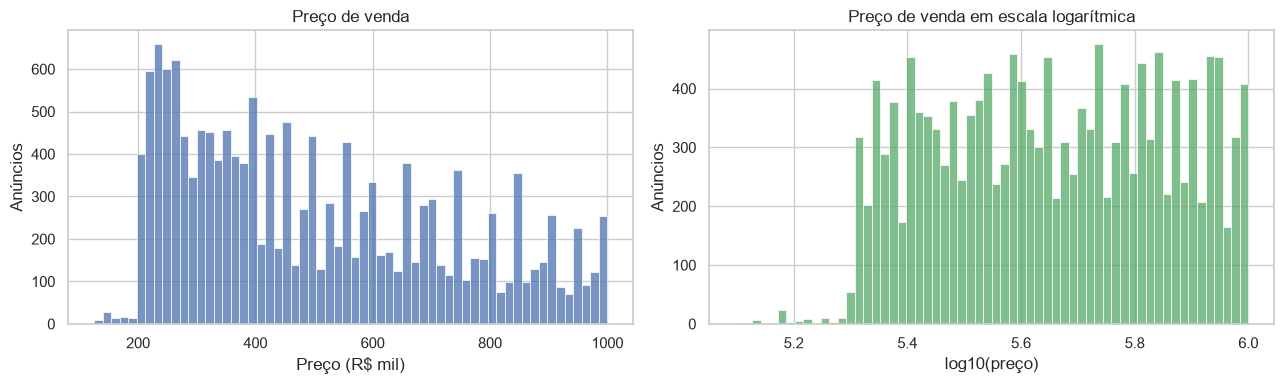

In [23]:
fig, eixos = plt.subplots(1, 2, figsize=(13, 4))

sns.histplot(df["preco"] / 1e3, bins=60, ax=eixos[0], color="#4C72B0")
eixos[0].set(title="Preço de venda", xlabel="Preço (R$ mil)", ylabel="Anúncios")

sns.histplot(np.log10(df["preco"]), bins=60, ax=eixos[1], color="#55A868")
eixos[1].set(title="Preço de venda em escala logarítmica", xlabel="log10(preço)", ylabel="Anúncios")

plt.tight_layout()
plt.show()

À esquerda, a assimetria e o corte abrupto em R$ 1 milhão, o limite da coleta. À direita, depois do log, a distribuição fica mais equilibrada. Daqui em diante o modelo prevê `log(preco)`, e as métricas são convertidas de volta para reais. O corte em R$ 1 milhão é uma característica da coleta que o modelo herda: ele nunca preverá valores muito acima disso.

## 7.2 Área: o principal fator de preço

Esperamos que imóveis maiores custem mais. Nos dois eixos em escala logarítmica, a relação deve aparecer como uma faixa inclinada.

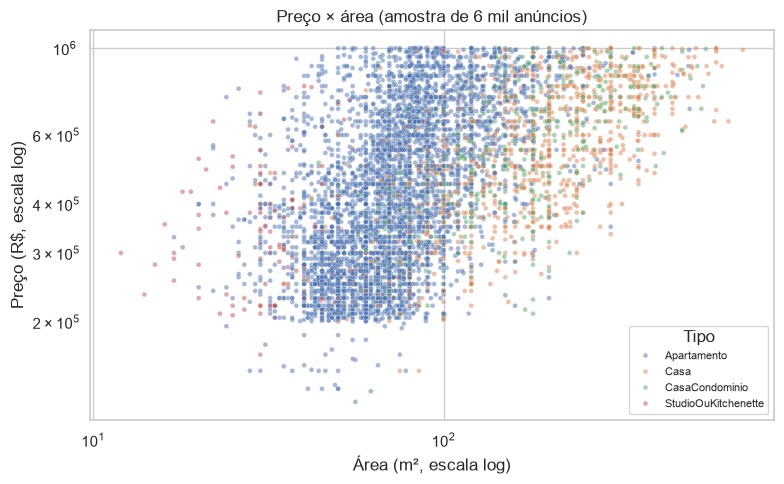

Correlação entre log(área) e log(preço): 0.54


In [24]:
amostra = df.sample(6000, random_state=SEMENTE)

fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=amostra, x="area_m2", y="preco", hue="tipo", s=12, alpha=0.5, ax=ax)
ax.set(xscale="log", yscale="log", title="Preço × área (amostra de 6 mil anúncios)",
       xlabel="Área (m², escala log)", ylabel="Preço (R$, escala log)")
ax.legend(title="Tipo", fontsize=8)
plt.tight_layout()
plt.show()

print(f"Correlação entre log(área) e log(preço): {np.corrcoef(np.log(df['area_m2']), np.log(df['preco']))[0, 1]:.2f}")

A relação é positiva e clara em escala log-log, mas a nuvem é larga: para a mesma área, o preço varia bastante. Parte dessa variação vem da localização, analisada a seguir. Nota-se também o "teto" horizontal em R$ 1 milhão: imóveis grandes em bairros caros, que valeriam mais, não estão na coleta.

## 7.3 Localização: preço do m² por bairro

Para isolar o efeito da localização, comparamos o **preço por m²**, que neutraliza a diferença de tamanho, nos 15 bairros com mais anúncios. Aqui usar o preço por m² não é problema, porque estamos só descrevendo os dados, não alimentando o modelo.

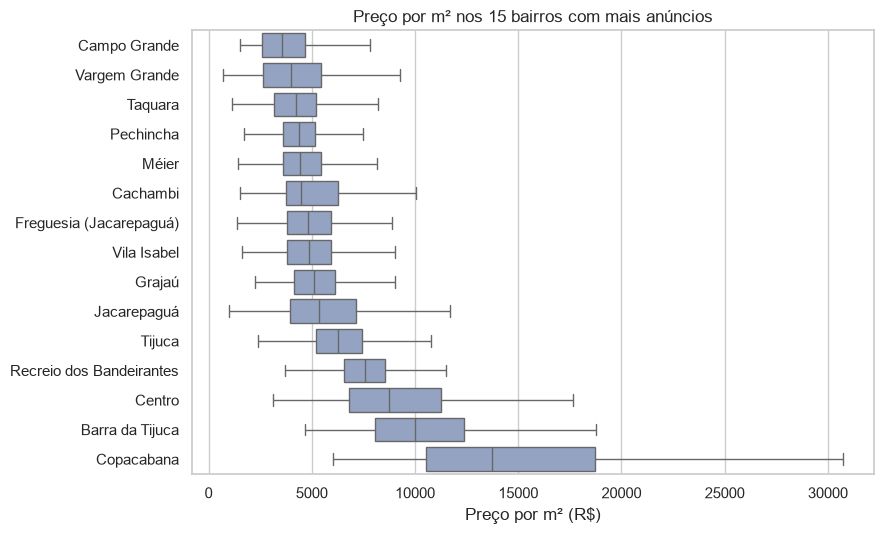

In [25]:
com_m2 = df.assign(preco_m2=df["preco"] / df["area_m2"])
principais = com_m2["bairro"].value_counts().head(15).index
ordem = com_m2[com_m2["bairro"].isin(principais)].groupby("bairro")["preco_m2"].median().sort_values().index

fig, ax = plt.subplots(figsize=(9, 5.5))
sns.boxplot(data=com_m2[com_m2["bairro"].isin(principais)], x="preco_m2", y="bairro",
            order=ordem, showfliers=False, color="#8DA0CB", ax=ax)
ax.set(title="Preço por m² nos 15 bairros com mais anúncios", xlabel="Preço por m² (R$)", ylabel="")
plt.tight_layout()
plt.show()

O m² mediano varia muito entre bairros: em Copacabana, o mais caro da lista, ele passa de R$ 13 mil, cerca de quatro vezes o de Campo Grande, o mais barato. Barra da Tijuca e Centro vêm logo atrás de Copacabana. A localização tem um efeito enorme, o que confirma que `bairro` e `regiao_qa` precisam entrar no modelo.

## 7.4 Demais atributos

Comparamos o preço mediano segundo o número de vagas e os itens de lazer, para verificar se esses atributos também carregam sinal.

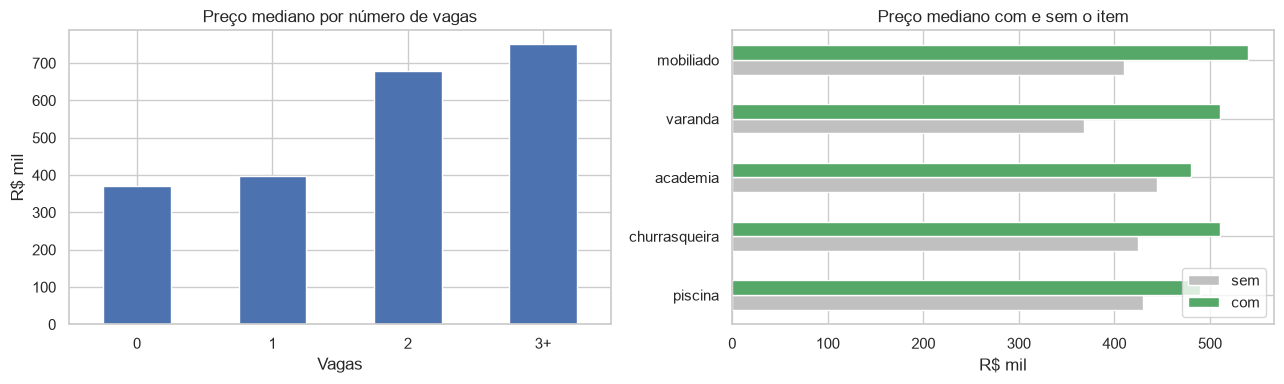

In [26]:
fig, eixos = plt.subplots(1, 2, figsize=(13, 4))

vagas = df.assign(vagas_grp=df["vagas"].clip(upper=3)).groupby("vagas_grp")["preco"].median() / 1e3
vagas.index = [f"{int(v)}" if v < 3 else "3+" for v in vagas.index]
vagas.plot.bar(ax=eixos[0], color="#4C72B0", rot=0)
eixos[0].set(title="Preço mediano por número de vagas", xlabel="Vagas", ylabel="R$ mil")

lazer = ["tem_piscina", "tem_churrasqueira", "tem_academia", "tem_varanda", "mobiliado"]
efeito = pd.DataFrame({
    "sem": [df.loc[df[c] == 0, "preco"].median() / 1e3 for c in lazer],
    "com": [df.loc[df[c] == 1, "preco"].median() / 1e3 for c in lazer],
}, index=[c.replace("tem_", "") for c in lazer])
efeito.plot.barh(ax=eixos[1], color=["#C0C0C0", "#55A868"])
eixos[1].legend(loc="lower right")
eixos[1].set(title="Preço mediano com e sem o item", xlabel="R$ mil", ylabel="")

plt.tight_layout()
plt.show()

O preço cresce de forma consistente com o número de vagas, e os imóveis com piscina, academia ou churrasqueira têm preço mediano maior. Parte desse efeito vem do tamanho (imóveis maiores costumam ter mais vagas e lazer), mas é exatamente esse tipo de relação combinada que um modelo de *machine learning* consegue separar.

**Conclusão da exploração:** todos os grupos de atributos (tamanho, localização, cômodos e lazer) mostram relação com o preço. A base tem sinal para a predição.

# 8. Prova de conceito: a base permite prever preços?

A melhor maneira de confirmar que o conjunto de dados serve para o objetivo é **treinar modelos e medir o erro em dados que eles nunca viram**. Não é a modelagem final (que é uma etapa posterior do trabalho), e sim um teste de viabilidade.

## 8.1 Separação entre treino e teste

Separamos 20% dos anúncios como **conjunto de teste**, guardado para a avaliação final. Tudo o que o modelo aprende (inclusive as medianas de imputação e a lista de bairros frequentes) sai apenas dos 80% de **treino**. Isso simula a situação real: o modelo é construído com dados conhecidos e aplicado a imóveis novos.

Estratificamos pelo tipo de imóvel para que treino e teste tenham a mesma proporção de apartamentos, casas e studios.

In [27]:
from sklearn.model_selection import train_test_split

ALVO = "preco"
X = df.drop(columns=[ALVO])
y = np.log(df[ALVO])  # modelamos log(preço), ver seção 7.1

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.2, random_state=SEMENTE, stratify=df["tipo"]
)
print(f"Treino: {len(X_treino):,} anúncios | Teste: {len(X_teste):,} anúncios")

Treino: 12,470 anúncios | Teste: 3,118 anúncios


## 8.2 Agrupamento dos bairros raros (P8)

Bairros com menos de 20 anúncios **no treino** passam a ser rotulados como "Outros (região)". Assim o modelo usa o efeito médio da região para eles, em vez de tentar aprender um efeito a partir de dois ou três exemplos. A lista de bairros frequentes é calculada só no treino e depois aplicada ao teste.

In [28]:
MIN_ANUNCIOS_BAIRRO = 20
bairros_frequentes = X_treino["bairro"].value_counts()
bairros_frequentes = set(bairros_frequentes[bairros_frequentes >= MIN_ANUNCIOS_BAIRRO].index)


def agrupar_bairros(X):
    X = X.copy()
    raro = ~X["bairro"].isin(bairros_frequentes)
    X.loc[raro, "bairro"] = "Outros (" + X.loc[raro, "regiao_qa"] + ")"
    return X


X_treino = agrupar_bairros(X_treino)
X_teste = agrupar_bairros(X_teste)

print(f"Bairros mantidos: {len(bairros_frequentes)} | categorias de bairro no treino: {X_treino['bairro'].nunique()}")
print(f"Anúncios de teste em bairros agrupados: {X_teste['bairro'].str.startswith('Outros').mean():.2%}")

Bairros mantidos: 75 | categorias de bairro no treino: 124
Anúncios de teste em bairros agrupados: 3.27%


## 8.3 Pipeline de pré-processamento

O pré-processamento é encapsulado em um `Pipeline` do scikit-learn, o que garante que exatamente as mesmas transformações aprendidas no treino sejam aplicadas no teste (e em qualquer imóvel novo):

- **atributos numéricos**: os ausentes são preenchidos pela mediana do treino. Para `area_m2`, `condominio` e `iptu` aplicamos `log(1 + x)`, pela mesma assimetria vista no preço;
- **atributos categóricos** (`tipo`, `bairro`, `regiao_qa`): *one-hot encoding*, que cria uma coluna 0/1 para cada categoria. Uma categoria que só aparece no teste é ignorada em vez de causar erro.

In [29]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder

NUM_LOG = ["area_m2", "condominio", "iptu"]
NUM = ["quartos", "banheiros", "suites", "vagas",
       "mobiliado", "tem_piscina", "tem_churrasqueira", "tem_academia", "tem_varanda"]
CAT = ["tipo", "bairro", "regiao_qa"]

assert set(NUM_LOG + NUM + CAT) == set(X_treino.columns), "Toda coluna deve ter um tratamento definido"

preprocessamento = ColumnTransformer([
    ("num_log", make_pipeline(SimpleImputer(strategy="median"), FunctionTransformer(np.log1p)), NUM_LOG),
    ("num", SimpleImputer(strategy="median"), NUM),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT),
])

## 8.4 Modelos comparados

Comparamos três abordagens, da mais simples à mais sofisticada:

1. **Referência ingênua: mediana do m² do bairro × área.** É o "cálculo de corretor": pegar o preço típico do m² no bairro e multiplicar pela área. Qualquer modelo útil precisa superar essa referência, senão não agrega nada.
2. **Regressão linear.** Modelo simples e interpretável, que assume que cada atributo soma (ou subtrai) um efeito fixo em `log(preço)`.
3. **Gradient Boosting (`HistGradientBoostingRegressor`).** Combina centenas de árvores de decisão e captura relações não lineares e interações (por exemplo, uma vaga a mais vale mais em Botafogo do que em Campo Grande).

## 8.5 Métricas de avaliação

- **MAE (erro absoluto médio, em R$):** quanto o modelo erra, em média, em reais;
- **MAPE (erro percentual absoluto médio):** o erro relativo ao preço do imóvel, a métrica mais intuitiva para o mercado imobiliário;
- **% de previsões com erro de até 15%:** a fração dos imóveis em que a estimativa fica "dentro da margem de negociação";
- **R² em `log(preço)`:** a fração da variação dos preços que o modelo explica (1 = perfeito, 0 = equivale a chutar a média).

As métricas em reais são calculadas depois de desfazer o log (`exp`).

In [30]:
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, r2_score


def avaliar(nome, log_previsto, log_real=y_teste):
    real, previsto = np.exp(log_real), np.exp(log_previsto)
    erro_relativo = np.abs(previsto - real) / real
    return {
        "modelo": nome,
        "MAE (R$)": mean_absolute_error(real, previsto),
        "MAPE": mean_absolute_percentage_error(real, previsto),
        "erro ≤ 15%": (erro_relativo <= 0.15).mean(),
        "R² (log)": r2_score(log_real, log_previsto),
    }

## 8.6 Treino e avaliação no conjunto de teste

In [31]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import LinearRegression

resultados = []

# 1. Referência: mediana do preço/m² do bairro (calculada no treino) x área
m2_treino = np.exp(y_treino) / X_treino["area_m2"]
m2_bairro = m2_treino.groupby(X_treino["bairro"]).median()
m2_teste = X_teste["bairro"].map(m2_bairro).fillna(m2_treino.median())
resultados.append(avaliar("Referência: m² do bairro × área", np.log(m2_teste * X_teste["area_m2"])))

# 2. Regressão linear
modelo_linear = Pipeline([("prep", preprocessamento), ("modelo", LinearRegression())])
modelo_linear.fit(X_treino, y_treino)
resultados.append(avaliar("Regressão linear", modelo_linear.predict(X_teste)))

# 3. Gradient Boosting
modelo_gb = Pipeline([
    ("prep", preprocessamento),
    ("modelo", HistGradientBoostingRegressor(max_iter=500, learning_rate=0.05, random_state=SEMENTE)),
])
modelo_gb.fit(X_treino, y_treino)
resultados.append(avaliar("Gradient Boosting", modelo_gb.predict(X_teste)))

tabela = pd.DataFrame(resultados).set_index("modelo")
formatos = {"MAE (R$)": "R$ {:,.0f}", "MAPE": "{:.1%}", "erro ≤ 15%": "{:.1%}", "R² (log)": "{:.3f}"}
tabela.apply(lambda col: col.map(formatos[col.name].format))

,MAE (R$),MAPE,erro ≤ 15%,R² (log)
modelo,,,,
Referência: m² do bairro × área,"R$ 165,148",31.2%,35.8%,0.379
Regressão linear,"R$ 85,888",17.6%,52.4%,0.773
Gradient Boosting,"R$ 78,773",16.3%,56.4%,0.793


**Leitura do resultado:**

- Os dois modelos de *machine learning* superam com folga a referência ingênua: o erro percentual médio cai de cerca de 31% para cerca de 17%. Ou seja, os atributos além de bairro e área (custos mensais, cômodos, vagas, lazer, tipo de imóvel) trazem informação útil.
- O Gradient Boosting tem o melhor desempenho em todas as métricas, com erro médio de cerca de R$ 80 mil e mais da metade das previsões dentro da margem de 15%. Isso indica relações não lineares e interações que a regressão linear não captura.
- **Sobre o R² (cerca de 0,80):** ele é menor do que seria em uma base com todas as faixas de preço, e isso é esperado. O R² mede a fração da **variação** dos preços que o modelo explica. Como a coleta vai só de R$ 125 mil a R$ 1 milhão, há bem menos variação para explicar do que em uma base que vai até R$ 20 milhões, onde a área sozinha já separa os imóveis baratos dos de luxo. Para o uso prático, a métrica mais relevante é o erro percentual, que é baixo.

## 8.7 Estabilidade: validação cruzada

Um único corte treino/teste pode ter dado sorte ou azar. Na **validação cruzada com 5 dobras**, o treino é dividido em 5 partes, e o modelo é treinado 5 vezes, cada vez testando em uma parte diferente. Se os resultados forem parecidos entre as dobras, o desempenho é estável e não depende de um corte específico.

In [32]:
from sklearn.model_selection import KFold, cross_val_score

validacao = KFold(n_splits=5, shuffle=True, random_state=SEMENTE)
r2_dobras = cross_val_score(modelo_gb, X_treino, y_treino, cv=validacao, scoring="r2")

print("R² (log) por dobra:", np.round(r2_dobras, 3))
print(f"Média: {r2_dobras.mean():.3f} | desvio-padrão: {r2_dobras.std():.3f}")

R² (log) por dobra: [0.799 0.794 0.81  0.791 0.79 ]
Média: 0.797 | desvio-padrão: 0.007


O desvio-padrão baixo entre as dobras mostra que o desempenho é consistente.

## 8.8 Previsto × real

O gráfico compara o preço previsto com o real no conjunto de teste. Em um modelo perfeito, todos os pontos cairiam sobre a diagonal tracejada.

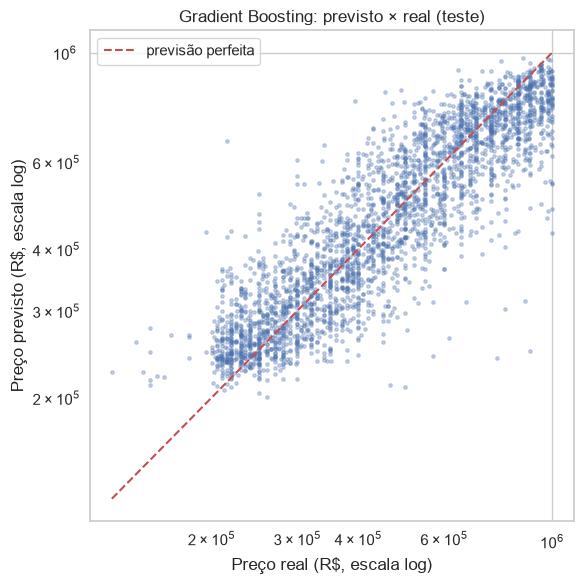

In [33]:
previsto_gb = np.exp(modelo_gb.predict(X_teste))
real = np.exp(y_teste)

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(real, previsto_gb, s=6, alpha=0.3, color="#4C72B0")
limites = [real.min(), real.max()]
ax.plot(limites, limites, "--", color="#C44E52", label="previsão perfeita")
ax.set(xscale="log", yscale="log", title="Gradient Boosting: previsto × real (teste)",
       xlabel="Preço real (R$, escala log)", ylabel="Preço previsto (R$, escala log)")
ax.legend()
plt.tight_layout()
plt.show()

Os pontos acompanham a diagonal, mas as **duas pontas ficam comprimidas**:

- **perto de R$ 1 milhão**, as previsões ficam abaixo do real: como a coleta não tem imóveis acima desse valor, o modelo "aprendeu" que o preço não passa de R$ 1 milhão e puxa para baixo os casos do topo;
- **abaixo de R$ 250 mil**, as previsões ficam acima do real: com a remoção dos anúncios no piso de R$ 200 mil (seção 6), sobraram poucos exemplos baratos, e o modelo dificilmente prevê valores tão baixos.

Esses dois efeitos são consequência dos limites da coleta e da remoção do piso, e não de defeitos do modelo. A dispersão restante vem de fatores que a base não registra: andar, vista, estado de conservação, idade do prédio e a margem de negociação embutida no preço anunciado.

## 8.9 Quais atributos mais importam?

A **importância por permutação** mede quanto o erro do modelo piora quando os valores de um atributo são embaralhados (o que destrói a informação dele). Quanto maior a piora, mais o modelo depende daquele atributo. A medida é calculada no conjunto de teste, sobre as colunas originais (antes do *one-hot*), o que facilita a leitura.

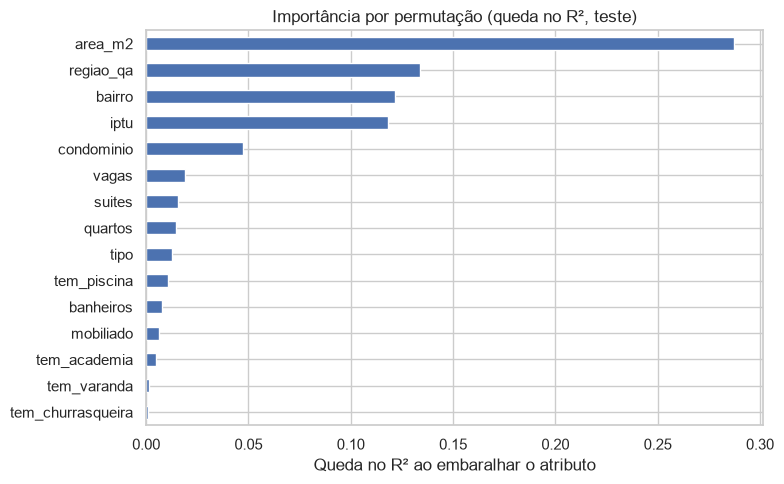

In [34]:
from sklearn.inspection import permutation_importance

importancia = permutation_importance(modelo_gb, X_teste, y_teste, n_repeats=5,
                                     random_state=SEMENTE, scoring="r2")
importancia = pd.Series(importancia.importances_mean, index=X_teste.columns).sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
importancia.plot.barh(ax=ax, color="#4C72B0")
ax.set(title="Importância por permutação (queda no R², teste)", xlabel="Queda no R² ao embaralhar o atributo")
plt.tight_layout()
plt.show()

**Área** e **localização** (bairro e região) estão entre os atributos dominantes, como esperado pela análise exploratória, acompanhados dos custos mensais (condomínio e IPTU), que funcionam como um "termômetro" do padrão do imóvel e do prédio.

Atributos como o número de quartos e os itens de lazer aparecem com importância baixa, mas isso não quer dizer que não influenciam o preço (a seção 7.4 mostrou que influenciam). Acontece que a informação deles já está quase toda contida em outros atributos: imóveis com mais quartos são maiores, e condomínios com piscina e academia são mais caros. Ao embaralhar só os quartos, o modelo continua sabendo a área e quase não perde desempenho. Isso é coerente com o funcionamento do mercado imobiliário e reforça que o modelo aprendeu relações reais, e não ruído ou vazamento.

# 9. Base final para modelagem

## 9.1 Gravação

A base limpa é gravada em CSV para as próximas etapas do trabalho. Gravamos a versão da seção 6, **antes** do agrupamento de bairros e da imputação. Essas transformações dependem da divisão treino/teste e devem ser refeitas, dentro do *pipeline*, em cada nova modelagem.

Usamos `encoding="utf-8-sig"` para que os acentos apareçam corretamente ao abrir o arquivo no Excel.

In [35]:
ARQUIVO_FINAL = "quintoandar_rio_modelagem_Vinicius_Machado.csv"
df.to_csv(ARQUIVO_FINAL, index=False, encoding="utf-8-sig")

# Conferência: o arquivo relido precisa ser igual à base em memória
relido = pd.read_csv(ARQUIVO_FINAL, encoding="utf-8-sig")
pd.testing.assert_frame_equal(relido, df, check_dtype=False)

print(f"Arquivo gravado: {ARQUIVO_FINAL} ({relido.shape[0]:,} linhas x {relido.shape[1]} colunas)")

Arquivo gravado: quintoandar_rio_modelagem_Vinicius_Machado.csv (15,588 linhas x 16 colunas)


## 9.2 Dicionário da base final

| Coluna | Tipo | Observação |
|---|---|---|
| `preco` | inteiro (R$) | **Alvo**. Entre R$ 125 mil e R$ 1 milhão, sem os anúncios no piso de R$ 200 mil. Modelar em `log` |
| `tipo` | categoria | `Apartamento`, `Casa`, `CasaCondominio`, `StudioOuKitchenette` |
| `bairro` | categoria | Padronizado. Agrupar os bairros raros a partir do treino (seção 8.2) |
| `regiao_qa` | categoria | Agrupamento de bairros do QuintoAndar, sem ausentes |
| `area_m2` | inteiro (m²) | Sem ausentes, mínimo de 10 m² |
| `condominio`, `iptu` | número (R$/mês) | Ausente onde o valor não foi informado ou era impossível. Zero é válido (casa de rua, isenção). Imputar no *pipeline* |
| `quartos`, `banheiros`, `vagas` | inteiro | Sem ausentes |
| `suites` | número | Ausente onde havia mais suítes que quartos |
| `mobiliado`, `tem_piscina`, `tem_academia`, `tem_churrasqueira`, `tem_varanda` | 0/1 | Sem ausentes |

# 10. Conclusão

## 10.1 Resposta à etapa 1

**Sim, criamos um conjunto de dados adequado para prever o preço de imóveis.**

- **Coleta própria por *scraping*** (seção 3): um robô que respeita o `robots.txt`, faz pausas entre as requisições e contorna a paginação instável da API dividindo a busca em faixas de preço. Ele gravou em CSV cerca de 18 mil anúncios próprios do QuintoAndar à venda no Rio até R$ 1 milhão, com preço, condomínio, IPTU, metragem, bairro e rua. A comparação com a base de referência do professor confirmou que os campos são lidos corretamente.
- **Limpeza** (seção 6): regras explícitas para o código −1, os valores impossíveis, as áreas e os preços por m² incoerentes, o piso de R$ 200 mil, as grafias de bairro e os anúncios repetidos.
- **Prova de conceito** (seção 8), no conjunto de teste:

| Modelo | Erro médio (MAPE) | Erro ≤ 15% | R² (log) |
|---|---|---|---|
| Referência: m² do bairro × área | 31,2% | 35,8% | 0,379 |
| Regressão linear | 17,6% | 52,4% | 0,773 |
| Gradient Boosting | **16,3%** | **56,4%** | **0,793** |

O Gradient Boosting reduz o erro percentual médio quase pela metade em relação à referência ingênua, o desempenho é estável na validação cruzada (R² entre 0,79 e 0,81 nas 5 dobras), e os atributos mais importantes (área, localização e custos mensais) são os que se esperaria do mercado, o que indica que não há vazamento de dados.

A limpeza preservou 86% dos anúncios. A maior perda foi a remoção consciente dos preços no piso de R$ 200 mil, cujo alvo não é confiável.

## 10.2 Limitações conhecidas

- **Segmento coberto.** A coleta vai só até R$ 1 milhão e só inclui os anúncios próprios do QuintoAndar (os classificados são bloqueados pelo `robots.txt`). O modelo vale para esse segmento e subestima os imóveis próximos do teto.
- **Imóveis mais baratos.** Os anúncios no piso de R$ 200 mil foram removidos, porque o preço deles não é confiável. O modelo tem poucos exemplos abaixo de R$ 250 mil.
- **Avaliação em dados limpos.** Os anúncios incoerentes foram removidos antes da divisão treino/teste (seção 6.1). As métricas valem para anúncios com dados consistentes.
- **Preço anunciado não é preço de venda.** O valor fechado costuma ser menor que o pedido. Para estimar o valor real de transação, seria interessante complementar com dados de transações (por exemplo, pela biblioteca `dadosimob`).
- **Um único dia de coleta.** O modelo descreve o mercado de outubro de 2026 e precisaria ser retreinado periodicamente. O *scraper* da seção 3 permite repetir a coleta e montar uma série histórica.
- **Fragilidade do *scraping*.** O *scraper* depende de uma API interna, não documentada, que pode mudar a qualquer momento. Por isso, cada coleta é gravada em um CSV próprio, e o notebook pode ser executado a partir do arquivo salvo.
- **Atributos ausentes na fonte.** Andar, idade do imóvel, vista, estado de conservação e coordenadas geográficas ajudariam a reduzir o erro restante.

## 10.3 Próximos passos

1. Ampliar a coleta para os imóveis acima de R$ 1 milhão, repetindo o *scraping* com outro limite de preço.
2. Ajustar os hiperparâmetros do Gradient Boosting e testar outros algoritmos (Random Forest, XGBoost, LightGBM).
3. Criar atributos derivados, como área por quarto ou a mediana do m² do bairro calculada no treino.
4. Analisar os erros por bairro e faixa de preço para identificar onde o modelo é menos confiável.